# Settings

In [256]:
using_upsampled_data = True
run_nsi_apodization = True
other_apodization = "rectangle".lower()

beamformed_apodized_matrix_name = "002_realpp_angle3"

# Imports

In [257]:
import numpy as np
import matplotlib.pyplot as plt
import json
from numba import njit
from scipy.signal import envelope

# Import parameters

In [258]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    interpolation_factor = params["simulation"]["interpolation_factor"] #interpolation factor   
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    upsampled_samples = samples + (interpolation_factor - 1) * (samples - 1)
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples
    params["simulation"]["upsampled_samples"] = upsampled_samples
    params["simulation"]["upsampled_sampling_rate"] = sampling_rate * interpolation_factor
    
    #more info
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])

    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Upsampled samples: ", upsampled_samples)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [259]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  791
Upsampled samples:  3161
Step size:  1.6e-08 s
Maximal acquisition depth: 0.009492 m
Lateral step:  2.25e-05 m


# Import RF matrix

In [260]:
objects = []

if using_upsampled_data: 
    samples = params["simulation"]["upsampled_samples"]
    sampling_rate = params["simulation"]["upsampled_sampling_rate"]
    rf_matrix_path = "./data/csv/rf_data/rf_matrix_upsampled_summed.npy"
else:
    samples = params["simulation"]["samples"]
    sampling_rate = params["wave"]["sampling_rate"]
    rf_matrix_path = "./data/csv/rf_data/rf_matrix_summed.npy"

rf_matrix_summed = np.load(rf_matrix_path)

In [261]:
@njit()
def find_object_effective_aperture(current_position, current_depth, aperture, array_length, pitch):
    effective_array_length =  current_depth / aperture
    first_transducer = -1
    transducers_in_effective_array = 0
    
    for j in range(0, array_length):
        if j*pitch >= current_position - effective_array_length / 2 and j*pitch <= current_position + effective_array_length / 2:
            if first_transducer == -1:
                first_transducer = j
            transducers_in_effective_array += 1
    
    return effective_array_length, transducers_in_effective_array, first_transducer         
        

# Apodization

## Apodization functions

In [262]:
@njit()
def generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0, mirror=False):
    result = np.zeros(array_length) + offset
    
    for transducer_idx in range(array_length):
        if transducer_idx - first_transducer >= 0:  # making sure we are in the effective array range
            transducer_relative_idx = transducer_idx - first_transducer
            if 0 <= transducer_relative_idx < transducers_in_effective_array / 2:
                result[transducer_idx] = (-1 if mirror else 1) + offset
            elif transducers_in_effective_array / 2 <= transducer_relative_idx < transducers_in_effective_array:
                result[transducer_idx] = (1 if mirror else -1) + offset
                
    return result

@njit()
def generate_rectangle_apodization(current_position, effective_array_length, array_length, amount_kept, pitch, offset=0):
    result = np.zeros(array_length)
    
    half_array = effective_array_length / 2
    amount_trimmed = (1 - amount_kept) * half_array
    
    for transducer_idx in range(array_length):
        position = transducer_idx * pitch
        lower_bound = current_position - half_array + amount_trimmed
        upper_bound = current_position + half_array - amount_trimmed
        
        if lower_bound <= position <= upper_bound:
            result[transducer_idx] = 1 + offset
        else:
            result[transducer_idx] = 0 + offset
                
    return result

In [263]:
@njit()
def apodization_wrapper(apodization_function, first_transducer, transducers_in_effective_array, effective_array_length, array_length, current_position, amount_kept, pitch, offset=0, mirror=False):
    
    match apodization_function:
        case "zm":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0, mirror=False)
        case "dc1":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0.1, mirror=False)
        case "dc2":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0.1, mirror=True)
        case "rectangle":
            return generate_rectangle_apodization(current_position, effective_array_length, array_length, amount_kept, pitch, offset=0)
        case _:
            return np.ones(array_length)

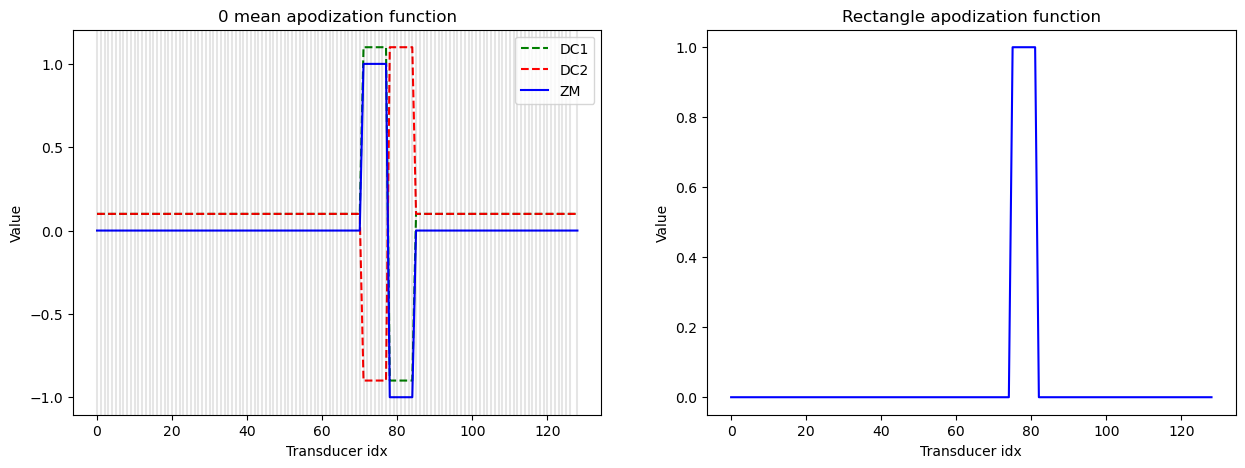

In [264]:
effective_array_length, transducers_in_effective_array, first_transducer = find_object_effective_aperture(0.007, 0.001, params["array"]["aperture"], params["array"]['length'], params["array"]["pitch"])

apodization_zm = apodization_wrapper("zm", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 0.007, 0.5, params["array"]["pitch"])
apodization_dc1 = apodization_wrapper("dc1", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 0.007, 0.5, params["array"]["pitch"])
apodization_dc2 = apodization_wrapper("dc2", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 0.007, 0.5, params["array"]["pitch"])
apodization_rectangle = apodization_wrapper("rectangle", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 0.007, 0.5, params["array"]["pitch"])

fig, ax = plt.subplots(1,2, figsize=(15, 5))

ax[0].plot(pos, apodization_dc1, color='g', ls='--', label='DC1')
ax[0].plot(pos, apodization_dc2, color='r', ls='--', label ='DC2')
ax[0].plot(pos, apodization_zm, color='b', label='ZM')
for x in pos:
    ax[0].axvline(x=x, color='black', ls='-', alpha=0.1)
ax[0].set_title('0 mean apodization function')
ax[0].set_xlabel('Transducer idx')
ax[0].set_ylabel('Value')
ax[0].legend()

ax[1].plot(pos, apodization_rectangle, color='b')
ax[1].set_title('Rectangle apodization function')
ax[1].set_xlabel('Transducer idx')
ax[1].set_ylabel('Value')
plt.show()

# Beamforming

In [265]:
def save_beamformed_data(bf_matrix, filename, destination="./data_nsi/csv/beamformed/"):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data saved at: {destination}{filename}.npy")

In [266]:
@njit(parallel=True)
def beamforming_opt(rf_summed_matrices, lateral_resolution, samples, total_depth, pitch, c, array_length, sampling_rate, aperture, apodization_function, angles = [0]):

    bf_matrix = np.zeros((samples, lateral_resolution, len(angles)))
    depth_step = (total_depth / 2) / samples #total depth in m / number of samples = depth per sample
    new_pitch = pitch * array_length / lateral_resolution #new pitch for the new lateral resolution
    
    print(f"Starting beamforming with {len(angles)} angles")
    print(f"Apodization function: {apodization_function}")
    print(f"Resolution: {lateral_resolution}x{samples}")
    
    for i in range(0, len(angles)): #for each angle
        print("   Beamforming for angle", angles[i], '°')

        cos_angle = np.cos(angles[i] * np.pi/180)
        sin_angle = np.sin(angles[i] * np.pi/180)

        for j in range(0, lateral_resolution): #for each lateral res sample

            for k in range(0, samples): #for vertical res sample

                depth = depth_step*k
                position = (pitch * array_length) * (j / lateral_resolution) #pitch isnt the same as the distance between transducers
                # we normalize the index to the total array length

                effective_array_length, transducers_in_effective_array, first_transducer = find_object_effective_aperture(position, depth, aperture, array_length, pitch)

                apodization = apodization_wrapper(
                    apodization_function, 
                    first_transducer, 
                    transducers_in_effective_array, 
                    effective_array_length, 
                    array_length, 
                    position, 
                    0.5, 
                    pitch
                )

                for l in range(0, array_length): #for each transducer
                    delay = ((depth * cos_angle + position * sin_angle) / c)  + (np.sqrt(depth**2 + (l * pitch - position)**2) / c)
                    delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)
                    if delay_idx < samples:
                        bf_matrix[k,j,i] += rf_summed_matrices[delay_idx, l, i] * apodization[l] #we use previously computed values for better perf

    print(f"Beamforming done - bf image shape: ", bf_matrix.shape)
    return bf_matrix

In [267]:
bf_nsi_matrices = []

nsi_apo_funcs = ["zm", "dc1", "dc2"]

if run_nsi_apodization:
    for apo_func in nsi_apo_funcs:
        bf_apodized_matrix = beamforming_opt(
            rf_matrix_summed, 
            params["simulation"]["lateral_resolution"], 
            samples, 
            params["simulation"]["total_depth"], 
            params["array"]["pitch"], 
            params["wave"]["c"], 
            params["array"]["length"], 
            sampling_rate, 
            params["array"]["aperture"],
            apo_func,
            angles= params["wave"]["angles"]
        )
        bf_nsi_matrices.append(bf_apodized_matrix)
        save_beamformed_data(bf_apodized_matrix, f"{beamformed_apodized_matrix_name}_{apo_func}", destination="./data_nsi/csv/beamformed_apodizations/")

else :
    bf_apodized_matrix = beamforming_opt(
        rf_matrix_summed, 
        params["simulation"]["lateral_resolution"], 
        samples, 
        params["simulation"]["total_depth"], 
        params["array"]["pitch"], 
        params["wave"]["c"], 
        params["array"]["length"], 
        sampling_rate, 
        params["array"]["aperture"],
        other_apodization,
        angles= params["wave"]["angles"]
    )
    save_beamformed_data(bf_apodized_matrix, f"{beamformed_apodized_matrix_name}_{other_apodization}", destination="./data_nsi/csv/beamformed_apodizations/")    

Starting beamforming with 7 angles
Apodization function: zm
Resolution: 512x3161
   Beamforming for angle -15 °
   Beamforming for angle -6 °
   Beamforming for angle -3 °
   Beamforming for angle 0 °
   Beamforming for angle 3 °
   Beamforming for angle 6 °
   Beamforming for angle 15 °
Beamforming done - bf image shape:  (3161, 512, 7)
Beamformed data saved at: ./data_nsi/csv/beamformed_apodizations/002_realpp_angle3_zm.npy
Starting beamforming with 7 angles
Apodization function: dc1
Resolution: 512x3161
   Beamforming for angle -15 °
   Beamforming for angle -6 °
   Beamforming for angle -3 °
   Beamforming for angle 0 °
   Beamforming for angle 3 °
   Beamforming for angle 6 °
   Beamforming for angle 15 °
Beamforming done - bf image shape:  (3161, 512, 7)
Beamformed data saved at: ./data_nsi/csv/beamformed_apodizations/002_realpp_angle3_dc1.npy
Starting beamforming with 7 angles
Apodization function: dc2
Resolution: 512x3161
   Beamforming for angle -15 °
   Beamforming for angle 

## Load saved matricies

In [268]:
bf_apodized_matrices_loaded = []

if run_nsi_apodization:
    for apo_func in nsi_apo_funcs:
        bf_apodized_matrices_loaded.append(np.load(f"./data_nsi/csv/beamformed_apodizations/{beamformed_apodized_matrix_name}_{apo_func}.npy"))
else :
    bf_apodized_matrices_loaded.append(np.load(f"./data_nsi/csv/beamformed_apodizations/{beamformed_apodized_matrix_name}_{other_apodization}.npy"))

In [269]:
bf_apodized_matrices_summed = [np.sum(bf_apodized_matrices_loaded, axis=2) for bf_apodized_matrices_loaded in bf_apodized_matrices_loaded]

## Envelopes

In [270]:
def get_envelope(bf_matrix, samples, lateral_resolution):
    env = np.zeros((samples, lateral_resolution))
    for i in range(0, lateral_resolution):
        env[:, i] = envelope(bf_matrix[:, i], residual=None)
    return env

In [271]:
if run_nsi_apodization:
    bf_matrix_zm = bf_apodized_matrices_summed[0]
    bf_matrix_dc1 = bf_apodized_matrices_summed[1]
    bf_matrix_dc2 = bf_apodized_matrices_summed[2]

    env_zm = get_envelope(bf_matrix_zm, samples, params["simulation"]["lateral_resolution"])
    env_dc1 = get_envelope(bf_matrix_dc1, samples, params["simulation"]["lateral_resolution"])
    env_dc2 = get_envelope(bf_matrix_dc2, samples, params["simulation"]["lateral_resolution"])
else:
    bf_matrix_apo = bf_apodized_matrices_summed[0]

## Average offsets and sum

In [272]:
if run_nsi_apodization:
    env_nsi = (env_dc1 + env_dc2) / 2 - env_zm
    save_beamformed_data(env_nsi, f"{beamformed_apodized_matrix_name}_env_nsi")
else:
    save_beamformed_data(bf_matrix_apo, f"{beamformed_apodized_matrix_name}_{other_apodization}")

Beamformed data saved at: ./data_nsi/csv/beamformed/002_realpp_angle3_env_nsi.npy


## Show beamformed image

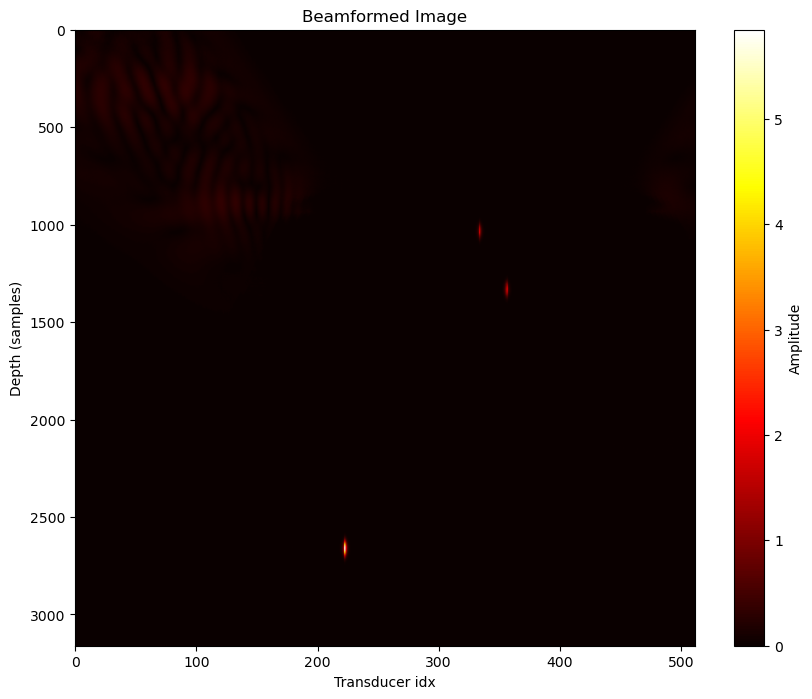

In [273]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(env_nsi if run_nsi_apodization else bf_matrix_apo), cmap='hot', aspect='auto')
plt.title("Beamformed Image")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data/images/bf_image_angles.png")
plt.show()